# 02 · Crossing baseline

Reference policy: at each decision time send the scheduled slice as a market order (paper §5, "crossing").
Experiment: 200 parent orders, Q = 500 shares, 20 steps of dt = 5 time units, TWAP schedule, default `SimParams`
(1 tick = 1 bp at mid0 = 10,000). Fresh simulator per order, alternating sides, common random numbers (D18).

What this notebook establishes: the cost of certainty. Crossing completes every order exactly on schedule
(completion = 1, deviation ≡ 0) and pays for it: half the spread on every share plus whatever it walks through.
Every later policy is compared against these numbers, with the same seeds.

In [2]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpc_execution.simulator import SimParams
from mpc_execution.schedule import twap, almgren_chriss
from mpc_execution.policies import Crossing
from mpc_execution.experiment import run_many
from mpc_execution.metrics import summarize, deviation

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
Q, N, DT, N_ORDERS = 500, 20, 5.0, 200
params = SimParams()
print(params)

SimParams(K=10, lambda0=2.0, alpha=1.2, theta=0.2, mu=1.0, qty_mean=50.0, mid0=10000, floor=100)


In [7]:
%%time
results = run_many(params, Crossing, DT, twap(Q, N), N_ORDERS, seed0=0)
df = pd.DataFrame(map(summarize, results))
df.head(6)

CPU times: user 22 s, sys: 99.2 ms, total: 22.1 s
Wall time: 22.1 s


,side,Q,filled,completion,fwap,market_vwap,swap,arrival_slippage_bps,vwap_slippage_bps,schedule_shortfall_bps,max_abs_deviation,final_deviation
0,BUY,500,500,1.0,10008.650,10008.276225,10008.025,0.149873,0.373466,0.624499,0,0
1,SELL,500,500,1.0,10006.264,10007.707867,10006.575,-3.763059,1.442755,0.310796,0,0
2,BUY,500,500,1.0,10001.824,10001.645999,10000.925,3.324499,0.177972,0.898917,0,0
3,SELL,500,500,1.0,10001.250,10001.426752,10002.075,2.249213,0.176726,0.824829,0,0
4,BUY,500,500,1.0,10000.200,9999.666568,9999.800,-0.299985,0.533450,0.400008,0,0
5,SELL,500,500,1.0,10001.150,10001.718080,10001.725,-1.650083,0.567982,0.574901,0,0


In [60]:
assert (df.completion == 1).all()
assert all(np.all(deviation(r) == 0) for r in results)
assert all(not e.passive for r in results for e in r.executions)
def levels_walked(r):
    """Extra price levels hit by our market orders (0 = every slice filled at the touch)."""
    ex = pd.DataFrame([(e.t, e.price) for e in r.executions], columns=["t", "price"])
    return int((ex.groupby("t").price.nunique() - 1).sum())

df["levels_walked"] = [levels_walked(r) for r in results]
df.levels_walked.describe()

count    200.000000
mean       1.025000
std        1.072439
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: levels_walked, dtype: float64

In [61]:
COLS = ["arrival_slippage_bps", "vwap_slippage_bps", "schedule_shortfall_bps"]

t = df[COLS].agg(["mean", "std"]).T
t["se"] = t["std"] / np.sqrt(len(df))
df_by_side = df.groupby("side")[COLS].mean().round(3).rename_axis(None)
buy = df_by_side.loc["BUY"]
sell = df_by_side.loc["SELL"]
se_diff = np.sqrt(2) * t["std"] / np.sqrt(len(df) / 2)
df_by_side.loc["|BUY−SELL| / se_diff"] = ((buy - sell).abs() / se_diff).round(2)


display(t.round(3))
display(df_by_side)

,mean,std,se
arrival_slippage_bps,0.997,3.463,0.245
vwap_slippage_bps,0.489,0.292,0.021
schedule_shortfall_bps,0.617,0.278,0.020


,arrival_slippage_bps,vwap_slippage_bps,schedule_shortfall_bps
BUY,0.745,0.491,0.596
SELL,1.249,0.488,0.639
|BUY−SELL| / se_diff,1.030,0.070,1.090


- `schedule_shortfall` is the pure execution cost: FWAP against the mid at each decision time. For crossing it is
  half the spread (≈ 0.5 bp when the spread is one tick) plus the price levels walked through. Small std. In our case we have 0.62 ± 0.02 bp; the excess comes from steps where the spread
  is 2 ticks (≈5% of the time, +0.03) and from slices that walk one level (see `levels_walked`: 1.025 on average).
- `arrival_slippage` adds the mid move during the order: zero mean by symmetry of the flow, except for our own
  impact, which pushes the mid in our direction. Much larger std (the mid diffuses over 100 time units). In our case we have 1.00 ± 0.25 bp = shortfall + the mid moving against us while we trade: 0.38 bp, which is exactly the average of the impact curve below over the 20 decision times. The two metrics are consistent.
- `vwap_slippage` 0.49 ± 0.02 bp, below the shortfall because the market VWAP includes our own trades
  (≈10% of the volume in the window) and the other agents' market orders also pay the spread.
- BUY and SELL agree within one standard error of the difference: no sign asymmetry (The two sides must agree within ~2 standard errors; a systematic gap would be a sign-convention bug).

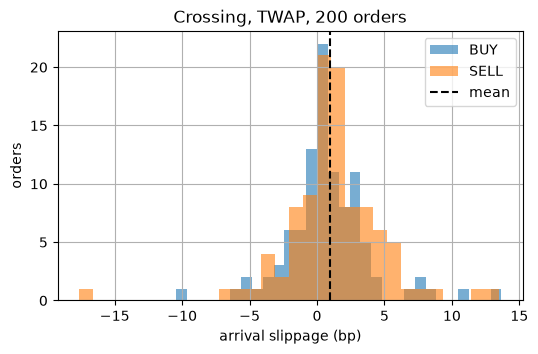

In [39]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for side, g in df.groupby("side"):
    ax.hist(g.arrival_slippage_bps, bins=30, alpha=0.6, label=side)
ax.axvline(df.arrival_slippage_bps.mean(), color="k", ls="--", label="mean")
ax.set(xlabel="arrival slippage (bp)", ylabel="orders", title="Crossing, TWAP, 200 orders")
ax.legend()
ax.grid()
fig.savefig(FIG / "02_arrival_slippage_hist.png", dpi=150, bbox_inches="tight")
plt.show()

Symmetric, centred at +1 bp, std 3.5 bp: for a single order the mid's diffusion over 100 time units
dominates the execution cost by an order of magnitude. This is why arrival slippage needs 200 orders to
resolve a 1 bp effect (se 0.25) while the schedule shortfall resolves 0.02 bp: comparisons between policies
must be made on the shortfall, or paired by seed.

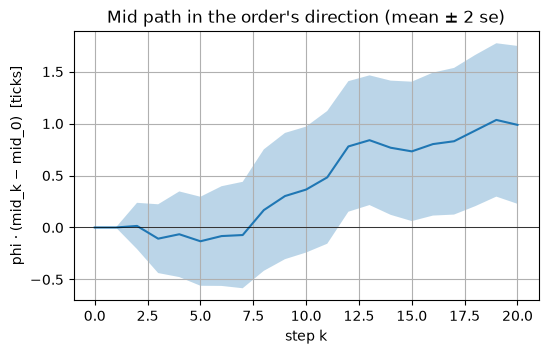

In [41]:
paths = np.array([r.side.value * (r.mids - r.mids[0]) for r in results])   # (orders, N+1), ticks
m, se = paths.mean(0), paths.std(0) / np.sqrt(len(paths))
k = np.arange(N + 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k, m)
ax.fill_between(k, m - 2 * se, m + 2 * se, alpha=0.3)
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="step k", ylabel="phi · (mid_k − mid_0)  [ticks]", title="Mid path in the order's direction (mean ± 2 se)")
ax.grid()
fig.savefig(FIG / "02_impact_path.png", dpi=150, bbox_inches="tight")
plt.show()

Our own impact: 500 shares bought in 20 slices move the mid by ≈ 1 tick (2 se ≈ 0.75) in our direction,
roughly linearly in executed volume; without our orders the signed path would average zero (D18).
Mechanism: each slice removes 25 shares from a touch that holds ≈ 275, and the flow refills it only on average.
The curve is flat for the first ~7 steps: at this size the effect is below the noise until it accumulates.

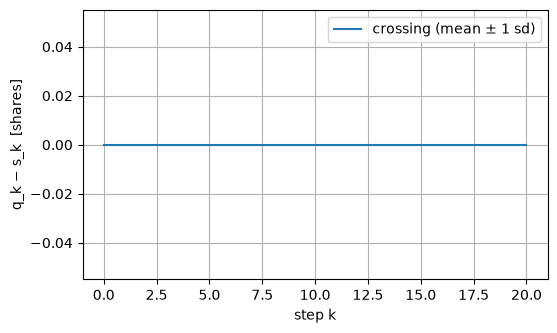

In [43]:
def deviation_band(results, ax, label):
    dev = np.array([deviation(r) for r in results])
    m, s = dev.mean(0), dev.std(0)
    ax.plot(m, label=f"{label} (mean ± 1 sd)")
    ax.fill_between(range(len(m)), m - s, m + s, alpha=0.3)

fig, ax = plt.subplots(figsize=(6, 3.5))
deviation_band(results, ax, "crossing")
ax.set(xlabel="step k", ylabel="q_k − s_k  [shares]")
ax.legend()
ax.grid()
fig.savefig(FIG / "02_deviation_path.png", dpi=150, bbox_inches="tight")
plt.show()

Identically zero by construction: crossing never leaves the schedule. The axes and the `deviation_band` helper
are kept for the MPC notebooks, where this band is the quantity the paper's Figure 8 fails to control.

In [62]:
results_ac = run_many(params, Crossing, DT, almgren_chriss(Q, N, psi=0.1), N_ORDERS, seed0=0)
df_ac = pd.DataFrame(map(summarize, results_ac))
pd.concat({"twap": table(df), "ac_psi=0.1": table(df_ac)}, axis=1)

twap               ac_psi=0.1              
                         mean    std     se       mean    std     se
arrival_slippage_bps    0.997  3.463  0.245      1.196  3.143  0.222
vwap_slippage_bps       0.489  0.292  0.021      0.361  0.951  0.067
schedule_shortfall_bps  0.617  0.278  0.020      0.646  0.359  0.025

Almgren–Chriss (psi = 0.1) front-loads the order and pays for it: arrival 1.20 vs 1.00 bp, shortfall 0.65 vs 0.62.
Bigger early slices walk the book more often and build the impact earlier, so more of the order trades
against a mid we have already pushed. The VWAP slippage std is three times larger because the schedule
is no longer aligned with the (flat) market volume profile.

## Conclusions

Crossing with TWAP, 200 orders of 500 shares over 20 steps:

| metric | mean | se |
|---|---|---|
| schedule shortfall | 0.62 bp | 0.02 |
| arrival slippage | 1.00 bp | 0.25 |
| VWAP slippage | 0.49 bp | 0.02 |
| completion | 1.00 | — |
| max deviation from schedule | 0 shares | — |

The cost of certainty is ≈ 0.6 bp per share of pure execution cost plus ≈ 0.4 bp of self-inflicted impact.
The room available to a smarter policy is bounded: a fully passive execution would earn half the spread
instead of paying it, i.e. a shortfall of about −0.5 bp, so the whole game is played within ≈ 1 bp per share,
and it is played against completion and schedule deviation, which crossing gets for free.

Target for MPC (notebook 03): schedule shortfall below 0.3 bp with completion ≥ 0.99 and
|q_k − s_k| within one slice (25 shares) along the path, on the same seeds.